# CS224N Assignment 1: Exploring Word Vectors (25 Points)
### <font color='blue'> Due 4:30pm, Tue April 9th 2024</font>

Welcome to CS224N! 

Before you start, make sure you **read the README.md** in the same directory as this notebook for important setup information. You need to install some Python libraries before you can successfully do this assignment. A lot of code is provided in this notebook, and we highly encourage you to read and understand it as part of the learning :)

If you aren't super familiar with Python, Numpy, or Matplotlib, we recommend you check out the review session on Friday. The session will be recorded and the material will be made available on our [website](http://web.stanford.edu/class/cs224n/index.html#schedule). The CS231N Python/Numpy [tutorial](https://cs231n.github.io/python-numpy-tutorial/) is also a great resource.


**Assignment Notes:** Please make sure to save the notebook as you go along. Submission Instructions are located at the bottom of the notebook.

# CS224N 作业 1：探索词向量（25 分）

### <font color='blue'> 截止时间：2024 年 4 月 9 日（星期二）下午 4:30</font>

欢迎来到 CS224N！

在开始之前，请务必**阅读与本 Notebook 位于同一目录下的 `README.md` 文件**，其中包含重要的环境配置说明。你需要安装一些 Python 库，才能顺利完成本次作业。

本 Notebook 已经提供了大量代码，我们强烈建议你在学习过程中仔细阅读并理解这些代码。:)

如果你对 Python、NumPy 或 Matplotlib 还不是非常熟悉，我们建议你参加周五的复习课。该课程将进行录制，相关学习资料也会发布在我们的[课程网站](http://web.stanford.edu/class/cs224n/index.html#schedule)上。

此外，CS231N 的 [Python/NumPy 教程](https://cs231n.github.io/python-numpy-tutorial/)也是非常好的学习资源。

**作业注意事项（Assignment Notes）：**

请务必在完成作业的过程中及时保存 Notebook。

作业提交说明位于本 Notebook 的底部。

In [1]:

# 所有 import 导入语句均在此处定义
# 注意：不要向此列表添加其他导入语句。
# ----------------

import sys
from tokenize import blank_re

assert sys.version_info[0] == 3
assert sys.version_info[1] >= 8

from platform import python_version
assert int(python_version().split(".")[1]) >= 5, "请按照与此 Notebook 位于同一目录下的 README.md 文件中的说明升级 Python 版本。你当前的 Python 版本是 " + python_version()

from gensim.models import KeyedVectors
from gensim.test.utils import datapath
import pprint
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [10, 5]

from datasets import load_dataset
imdb_dataset = load_dataset("stanfordnlp/imdb")

import re
import numpy as np
import random
import scipy as sp
from sklearn.decomposition import TruncatedSVD
from sklearn.decomposition import PCA

START_TOKEN = '<START>'
END_TOKEN = '<END>'
NUM_SAMPLES = 150

np.random.seed(0)
random.seed(0)
# ----------------


## Word Vectors

Word Vectors are often used as a fundamental component for downstream NLP tasks, e.g. question answering, text generation, translation, etc., so it is important to build some intuitions as to their strengths and weaknesses. Here, you will explore two types of word vectors: those derived from *co-occurrence matrices*, and those derived via *GloVe*. 

**Note on Terminology:** The terms "word vectors" and "word embeddings" are often used interchangeably. The term "embedding" refers to the fact that we are encoding aspects of a word's meaning in a lower dimensional space. As [Wikipedia](https://en.wikipedia.org/wiki/Word_embedding) states, "*conceptually it involves a mathematical embedding from a space with one dimension per word to a continuous vector space with a much lower dimension*".

## 词向量（Word Vectors）

词向量通常是下游自然语言处理（NLP）任务（例如问答、文本生成、机器翻译等）的基础组成部分。因此，建立对词向量优势与局限性的直观认识非常重要。

在本次作业中，你将探索两种类型的词向量：

1. **基于共现矩阵（Co-occurrence Matrices）** 构建的词向量。
2. **基于 GloVe（Global Vectors for Word Representation）** 方法学习得到的词向量。

**术语说明（Note on Terminology）：**

“词向量”（Word Vectors）和“词嵌入”（Word Embeddings）这两个术语通常可以互换使用。

“嵌入”（Embedding）这一术语指的是：我们将词语含义的某些方面编码到一个较低维度的空间中。

正如 [Wikipedia](https://en.wikipedia.org/wiki/Word_embedding) 所述：

> 从概念上讲，词嵌入涉及一种数学映射：将每个词对应一个维度的空间，映射到维度低得多的连续向量空间中。

## Part 1: Count-Based Word Vectors (10 points)

Most word vector models start from the following idea:

*You shall know a word by the company it keeps ([Firth, J. R. 1957:11](https://en.wikipedia.org/wiki/John_Rupert_Firth))*

Many word vector implementations are driven by the idea that similar words, i.e., (near) synonyms, will be used in similar contexts. As a result, similar words will often be spoken or written along with a shared subset of words, i.e., contexts. By examining these contexts, we can try to develop embeddings for our words. With this intuition in mind, many "old school" approaches to constructing word vectors relied on word counts. Here we elaborate upon one of those strategies, *co-occurrence matrices* (for more information, see [here](https://web.stanford.edu/~jurafsky/slp3/6.pdf) or [here](https://web.archive.org/web/20190530091127/https://medium.com/data-science-group-iitr/word-embedding-2d05d270b285)).

## 第一部分：基于计数的词向量（Count-Based Word Vectors）（10 分）

大多数词向量模型都源于以下思想：

*“观其伴，知其义。”（You shall know a word by the company it keeps.）* —— [Firth, J. R.（1957:11）](https://en.wikipedia.org/wiki/John_Rupert_Firth)

许多词向量的实现方法都基于这样一个思想：**相似的词语，即（近）同义词，往往出现在相似的上下文（Context）中。**

因此，相似的词语在口语或书面语中，通常会与一部分相同的词语共同出现，而这些共同出现的词语就构成了它们的上下文。

通过分析这些上下文，我们可以尝试为词语构建词嵌入（Word Embeddings）。

基于这一直观思想，许多传统的词向量构建方法依赖于**词频计数（Word Counts）**。

在这一部分，我们将详细介绍其中一种方法：**共现矩阵（Co-occurrence Matrices）**。

更多相关信息可参考：

- [参考资料 1：Stanford《Speech and Language Processing》](https://web.stanford.edu/~jurafsky/slp3/6.pdf)
- [参考资料 2：Word Embedding 介绍](https://web.archive.org/web/20190530091127/https://medium.com/data-science-group-iitr/word-embedding-2d05d270b285)

### Co-Occurrence

A co-occurrence matrix counts how often things co-occur in some environment. Given some word $w_i$ occurring in the document, we consider the *context window* surrounding $w_i$. Supposing our fixed window size is $n$, then this is the $n$ preceding and $n$ subsequent words in that document, i.e. words $w_{i-n} \dots w_{i-1}$ and $w_{i+1} \dots w_{i+n}$. We build a *co-occurrence matrix* $M$, which is a symmetric word-by-word matrix in which $M_{ij}$ is the number of times $w_j$ appears inside $w_i$'s window among all documents.

**Example: Co-Occurrence with Fixed Window of n=1**:

Document 1: "all that glitters is not gold"

Document 2: "all is well that ends well"


|     *    | `<START>` | all | that | glitters | is   | not  | gold  | well | ends | `<END>` |
|----------|-------|-----|------|----------|------|------|-------|------|------|-----|
| `<START>`    | 0     | 2   | 0    | 0        | 0    | 0    | 0     | 0    | 0    | 0   |
| all      | 2     | 0   | 1    | 0        | 1    | 0    | 0     | 0    | 0    | 0   |
| that     | 0     | 1   | 0    | 1        | 0    | 0    | 0     | 1    | 1    | 0   |
| glitters | 0     | 0   | 1    | 0        | 1    | 0    | 0     | 0    | 0    | 0   |
| is       | 0     | 1   | 0    | 1        | 0    | 1    | 0     | 1    | 0    | 0   |
| not      | 0     | 0   | 0    | 0        | 1    | 0    | 1     | 0    | 0    | 0   |
| gold     | 0     | 0   | 0    | 0        | 0    | 1    | 0     | 0    | 0    | 1   |
| well     | 0     | 0   | 1    | 0        | 1    | 0    | 0     | 0    | 1    | 1   |
| ends     | 0     | 0   | 1    | 0        | 0    | 0    | 0     | 1    | 0    | 0   |
| `<END>`      | 0     | 0   | 0    | 0        | 0    | 0    | 1     | 1    | 0    | 0   |

In NLP, we commonly use `<START>` and `<END>` tokens to mark the beginning and end of sentences, paragraphs, or documents. These tokens are included in co-occurrence counts, encapsulating each document, for example: "`<START>` All that glitters is not gold `<END>`".

The matrix rows (or columns) provide word vectors based on word-word co-occurrence, but they can be large. To reduce dimensionality, we employ Singular Value Decomposition (SVD), akin to PCA, selecting the top $k$ principal components. The SVD process decomposes the co-occurrence matrix $A$ into singular values in the diagonal $S$ matrix and new, shorter word vectors in $U_k$.

This dimensionality reduction maintains semantic relationships; for instance, *doctor* and *hospital* will be closer than *doctor* and *dog*.

For those unfamiliar with eigenvalues and SVD, a beginner-friendly introduction to SVD is available [here](https://davetang.org/file/Singular_Value_Decomposition_Tutorial.pdf). Additional resources for in-depth understanding include lectures [7](https://web.stanford.edu/class/cs168/l/l7.pdf), [8](http://theory.stanford.edu/~tim/s15/l/l8.pdf), and [9](https://web.stanford.edu/class/cs168/l/l9.pdf) of CS168, providing high-level treatment of these algorithms. For practical implementation, utilizing pre-programmed functions from Python packages like numpy, scipy, or sklearn is recommended. While applying full SVD to large corpora can be memory-intensive, scalable techniques such as Truncated SVD exist for extracting the top $k$ vector components efficiently.

### 共现（Co-Occurrence）

共现矩阵（Co-occurrence Matrix）用于统计在特定环境中，不同事物共同出现的频率。

给定文档中出现的某个词 $w_i$，我们考虑其周围的**上下文窗口（Context Window）**。

假设固定窗口大小为 $n$，那么上下文窗口包含该文档中 $w_i$ 前面的 $n$ 个词和后面的 $n$ 个词，即：

- 前面的词：$w_{i-n} \dots w_{i-1}$
- 后面的词：$w_{i+1} \dots w_{i+n}$

我们构建一个**共现矩阵（Co-occurrence Matrix）** $M$。这是一个对称的词-词矩阵（Word-by-Word Matrix），其中 $M_{ij}$ 表示在所有文档中，词 $w_j$ 出现在词 $w_i$ 的上下文窗口内的总次数。

**示例：固定窗口大小 $n=1$ 的共现矩阵**

文档 1（Document 1）：

"all that glitters is not gold"

文档 2（Document 2）：

"all is well that ends well"

| | `<START>` | all | that | glitters | is | not | gold | well | ends | `<END>` |
|---|---|---|---|---|---|---|---|---|---|---|
| `<START>` | 0 | 2 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 |
| all | 2 | 0 | 1 | 0 | 1 | 0 | 0 | 0 | 0 | 0 |
| that | 0 | 1 | 0 | 1 | 0 | 0 | 0 | 1 | 1 | 0 |
| glitters | 0 | 0 | 1 | 0 | 1 | 0 | 0 | 0 | 0 | 0 |
| is | 0 | 1 | 0 | 1 | 0 | 1 | 0 | 1 | 0 | 0 |
| not | 0 | 0 | 0 | 0 | 1 | 0 | 1 | 0 | 0 | 0 |
| gold | 0 | 0 | 0 | 0 | 0 | 1 | 0 | 0 | 0 | 1 |
| well | 0 | 0 | 1 | 0 | 1 | 0 | 0 | 0 | 1 | 1 |
| ends | 0 | 0 | 1 | 0 | 0 | 0 | 0 | 1 | 0 | 0 |
| `<END>` | 0 | 0 | 0 | 0 | 0 | 0 | 1 | 1 | 0 | 0 |

在自然语言处理（NLP）中，我们通常使用 `<START>` 和 `<END>` 这两个特殊标记（Tokens），分别表示句子、段落或文档的开始和结束。

这些标记也会被纳入共现次数的统计，并放置在每个文档的首尾。例如：

`<START> All that glitters is not gold <END>`

共现矩阵的每一行（或每一列）都可以作为一个词向量，用于表示词语之间的共现关系。然而，这些词向量的维度可能非常高。

为了降低维度，我们采用**奇异值分解（Singular Value Decomposition，SVD）**。这种方法与主成分分析（Principal Component Analysis，PCA）类似，通过选择前 $k$ 个主成分来实现降维。

SVD 将共现矩阵 $A$ 分解，其中：

- 对角矩阵 $S$ 包含奇异值（Singular Values）。
- 矩阵 $U_k$ 包含新的、维度更低的词向量。

这种降维方法能够保留词语之间的语义关系。例如，*doctor*（医生）与 *hospital*（医院）之间的距离通常比 *doctor*（医生）与 *dog*（狗）之间的距离更近。

对于不熟悉特征值（Eigenvalues）和 SVD 的同学，可以参考这份适合初学者的 [SVD 入门教程](https://davetang.org/file/Singular_Value_Decomposition_Tutorial.pdf)。

如果希望深入理解这些算法，还可以参考 CS168 的以下课程讲义：

- [Lecture 7](https://web.stanford.edu/class/cs168/l/l7.pdf)
- [Lecture 8](http://theory.stanford.edu/~tim/s15/l/l8.pdf)
- [Lecture 9](https://web.stanford.edu/class/cs168/l/l9.pdf)

这些讲义从较高层次介绍了相关算法。

在实际编程实现中，建议使用 Python 库（例如 `numpy`、`scipy` 或 `sklearn`）中已经实现好的函数。

需要注意的是，对大规模语料库（Corpus）执行完整的 SVD 可能消耗大量内存。不过，我们可以采用更具可扩展性的技术，例如**截断奇异值分解（Truncated SVD）**，以高效地提取前 $k$ 个向量分量。

### Plotting Co-Occurrence Word Embeddings

Here, we will be using the Large Movie Review Dataset. This is a dataset for binary sentiment classification containing substantially more data than previous benchmark datasets. We provide a set of 25,000 highly polar movie reviews for training, and 25,000 for testing. There is additional unlabeled data for use as well. We provide a `read_corpus` function below that pulls out the text of a movie review from the dataset. The function also adds `<START>` and `<END>` tokens to each of the documents, and lowercases words. You do **not** have to perform any other kind of pre-processing.

### 共现词嵌入的可视化（Plotting Co-Occurrence Word Embeddings）

在这一部分，我们将使用**大型电影评论数据集（Large Movie Review Dataset）**。

这是一个用于**二分类情感分析（Binary Sentiment Classification）**的数据集，其数据量远大于以往的基准数据集。

该数据集包含：

- **25,000 条**情感倾向鲜明的电影评论，用于训练。
- **25,000 条**电影评论，用于测试。
- 此外，还提供了额外的无标签数据（Unlabeled Data）供使用。

我们在下方提供了一个 `read_corpus` 函数，用于从数据集中提取电影评论的文本内容。

该函数还会对每篇文档进行以下处理：

1. 在文档开头添加 `<START>` 标记。
2. 在文档结尾添加 `<END>` 标记。
3. 将所有单词转换为小写（Lowercase）。

你**不需要执行任何其他形式的预处理（Pre-processing）**。

In [2]:

def read_corpus():
    """
    从大型电影评论数据集（Large Movie Review Dataset）中读取文件。

    参数：
        category (string)：类别名称。

    返回：
        二维列表（list of lists），其中每个子列表包含一个经过处理的文件中的单词。
    """
    files = imdb_dataset["train"]["text"][:NUM_SAMPLES]
    return [[START_TOKEN] + [re.sub(r'[^\w]', '', w.lower()) for w in f.split(" ")] + [END_TOKEN] for f in files]


Let's have a look what these documents are like….

In [3]:
imdb_corpus = read_corpus()
pprint.pprint(imdb_corpus[:3], compact=True, width=100)
print("corpus size: ", len(imdb_corpus[0]))

[['<START>', 'i', 'rented', 'i', 'am', 'curiousyellow', 'from', 'my', 'video', 'store', 'because',
  'of', 'all', 'the', 'controversy', 'that', 'surrounded', 'it', 'when', 'it', 'was', 'first',
  'released', 'in', '1967', 'i', 'also', 'heard', 'that', 'at', 'first', 'it', 'was', 'seized',
  'by', 'us', 'customs', 'if', 'it', 'ever', 'tried', 'to', 'enter', 'this', 'country', 'therefore',
  'being', 'a', 'fan', 'of', 'films', 'considered', 'controversial', 'i', 'really', 'had', 'to',
  'see', 'this', 'for', 'myselfbr', 'br', 'the', 'plot', 'is', 'centered', 'around', 'a', 'young',
  'swedish', 'drama', 'student', 'named', 'lena', 'who', 'wants', 'to', 'learn', 'everything',
  'she', 'can', 'about', 'life', 'in', 'particular', 'she', 'wants', 'to', 'focus', 'her',
  'attentions', 'to', 'making', 'some', 'sort', 'of', 'documentary', 'on', 'what', 'the', 'average',
  'swede', 'thought', 'about', 'certain', 'political', 'issues', 'such', 'as', 'the', 'vietnam',
  'war', 'and', 'race', 'issu

### Question 1.1: Implement `distinct_words` [code] (2 points)

Write a method to work out the distinct words (word types) that occur in the corpus.

You can use `for` loops to process the input `corpus` (a list of list of strings), but try using Python list comprehensions (which are generally faster). In particular, [this](https://coderwall.com/p/rcmaea/flatten-a-list-of-lists-in-one-line-in-python) may be useful to flatten a list of lists. If you're not familiar with Python list comprehensions in general, here's [more information](https://python-3-patterns-idioms-test.readthedocs.io/en/latest/Comprehensions.html).

Your returned `corpus_words` should be sorted. You can use python's `sorted` function for this.

You may find it useful to use [Python sets](https://www.w3schools.com/python/python_sets.asp) to remove duplicate words.

### 问题 1.1：实现 `distinct_words` 函数 [编程题]（2 分）

编写一个函数，找出语料库（Corpus）中出现的所有**不同单词（Distinct Words，也称为 Word Types）**。

你可以使用 `for` 循环来处理输入的 `corpus`（一个由字符串列表组成的列表，即 `list of list of strings`），但建议尝试使用 **Python 列表推导式（List Comprehensions）**，因为它通常具有更快的执行速度。

特别是，[这篇教程](https://coderwall.com/p/rcmaea/flatten-a-list-of-lists-in-one-line-in-python)可能对你有所帮助，它介绍了如何使用一行代码将嵌套列表展平（Flatten）。

如果你不熟悉 Python 列表推导式，可以参考[这份教程](https://python-3-patterns-idioms-test.readthedocs.io/en/latest/Comprehensions.html)。

返回的 `corpus_words` 必须经过**排序（Sorted）**。你可以使用 Python 内置的 `sorted()` 函数来完成排序。

此外，你可能会发现使用 [Python 集合（Set）](https://www.w3schools.com/python/python_sets.asp)来去除重复单词非常有用。

In [4]:
def distinct_words(corpus):
    """
    确定语料库中所有不重复的单词列表。

    参数：
        corpus (list of list of strings): 由多个文档组成的语料库，每个文档是一个字符串列表。

    返回：
        corpus_words (list of strings): 语料库中所有不重复单词组成的已排序列表。
        n_corpus_words (integer): 语料库中不重复单词的数量。
    """
    corpus_words = []
    n_corpus_words = -1

    # ------------------
    # 在此处编写你的实现代码。

    # 遍历
    for document in corpus:
        for word in document:
            if word not in corpus_words: # 如果单词没有出现过，就添加到列表中
                corpus_words.append(word)


    # 对单词排序
    corpus_words.sort()

    # 统计不重复单词的数量
    n_corpus_words = len(corpus_words)

    # ------------------

    return corpus_words, n_corpus_words


In [5]:

def distinct_words_listcomp(corpus):
    """
    确定语料库中所有不重复的单词列表。

    参数：
        corpus (list of list of strings): 由多个文档组成的语料库，每个文档是一个字符串列表。

    返回：
        corpus_words (list of strings): 语料库中所有不重复单词组成的已排序列表。
        n_corpus_words (integer): 语料库中不重复单词的数量。
    """
    corpus_words = []
    n_corpus_words = -1

    # ------------------
    # 在此处编写你的实现代码。

    # 使用列表推导式展平二维列表
    words = [word for document in corpus for word in document]

    # 使用 set 去重，并排序
    corpus_words = sorted(set(words))

    # 统计不重复单词的数量
    n_corpus_words = len(corpus_words)

    # ------------------

    return corpus_words, n_corpus_words


In [6]:
# ---------------------
# 运行此基础检查
# 注意：该测试并不能全面验证代码的正确性。
# ---------------------

# 定义一个用于测试的小型语料库
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "), "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
test_corpus_words, num_corpus_words = distinct_words(test_corpus)

# 正确答案
ans_test_corpus_words = sorted([START_TOKEN, "All", "ends", "that", "gold", "All's", "glitters", "isn't", "well", END_TOKEN])
ans_num_corpus_words = len(ans_test_corpus_words)

# 测试不重复单词的数量是否正确
assert(num_corpus_words == ans_num_corpus_words), "不重复单词数量错误。正确答案：{}。你的答案：{}".format(ans_num_corpus_words, num_corpus_words)

# 测试返回的单词列表是否正确
assert (test_corpus_words == ans_test_corpus_words), "corpus_words 不正确。\n正确答案：{}\n你的答案：{}".format(str(ans_test_corpus_words), str(test_corpus_words))

# 打印测试成功信息
print ("-" * 80)
print("通过所有测试！")
print ("-" * 80)

# 测试进阶版
advanced_words, advanced_num = distinct_words_listcomp(test_corpus)

assert advanced_words == test_corpus_words
assert advanced_num == num_corpus_words

print("通过所有测试!")


--------------------------------------------------------------------------------
通过所有测试！
--------------------------------------------------------------------------------
通过所有测试!


### Question 1.2: Implement `compute_co_occurrence_matrix` [code] (3 points)

Write a method that constructs a co-occurrence matrix for a certain window-size $n$ (with a default of 4), considering words $n$ before and $n$ after the word in the center of the window. Here, we start to use `numpy (np)` to represent vectors, matrices, and tensors. If you're not familiar with NumPy, there's a NumPy tutorial in the second half of this cs231n [Python NumPy tutorial](http://cs231n.github.io/python-numpy-tutorial/).

### 问题 1.2：实现 `compute_co_occurrence_matrix` [编程题]（3 分）

编写一个函数，构建指定窗口大小（window size）\(n\) 的**共现矩阵（co-occurrence matrix）**，其中 \(n\) 的默认值为 4。

对于窗口中心的某个单词，需要同时考虑它**前面的 \(n\) 个单词和后面的 \(n\) 个单词**。

从这里开始，我们将使用 `numpy (np)` 来表示向量（vectors）、矩阵（matrices）和张量（tensors）。

如果你还不熟悉 NumPy，可以参考 CS231n 的 [Python NumPy 教程](http://cs231n.github.io/python-numpy-tutorial/)，其中后半部分介绍了 NumPy。


In [7]:

def compute_co_occurrence_matrix(corpus, window_size=4):
    """
    根据给定的语料库和窗口大小，计算共现矩阵（默认窗口大小为 4）。

    注意：
        文档中的每个单词都应依次作为窗口的中心词。
        靠近文档边界的单词，其共现词数量会更少。

        例如，对于文档
        "<START> All that glitters is not gold <END>"
        当窗口大小为 4 时，
        "All" 将与 "<START>"、"that"、"glitters"、
        "is" 和 "not" 发生共现。

    参数：
        corpus (list of list of strings):
            语料库，由多个文档组成，每个文档是一个字符串列表。

        window_size (int):
            上下文窗口大小。

    返回：
        M (numpy 矩阵):
            形状为 (语料库中不同单词的数量, 语料库中不同单词的数量)
            的对称共现矩阵。

            矩阵中的元素表示单词之间的共现次数。
            矩阵行和列对应的单词顺序，必须与
            distinct_words 函数返回的单词顺序一致。

        word2ind (dict):
            将单词映射到矩阵 M 中对应索引
            （即行号或列号）的字典。
    """
    words, n_words = distinct_words(corpus)
    M = None
    word2ind = {}

    # ------------------
    # 在此处编写你的实现代码。

    # 1. 建立单词和索引的对应关系
    for i in range(n_words):
        word2ind[words[i]] = i

    # 2. 初始化共现矩阵
    M = np.zeros((n_words, n_words))

    # 3.遍历每篇文档
    for document in corpus:
        # 4. 遍历每个中心词
        for i in range(len(document)):
            center_word = document[i]

            # 确定窗口边界
            start = max(0, i-window_size) # 防止溢出文档边界
            end = min(len(document), i+window_size+1)

            # 5. 遍历上下文词
            for j in range(start, end):
                if i != j:
                    context_word = document[j]

                    # 更新共现次数
                    M[word2ind[center_word], word2ind[context_word]] += 1

    # ------------------

    return M, word2ind


In [8]:

# ---------------------
# 运行此基础检查
# 注意：该测试并不能全面验证代码的正确性。
# ---------------------

# 定义一个小型测试语料库，并获取学生实现的共现矩阵
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "), "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
M_test, word2ind_test = compute_co_occurrence_matrix(test_corpus, window_size=1)

# 正确的共现矩阵 M 和单词索引字典 word2ind
M_test_ans = np.array(
    [[0., 0., 0., 0., 0., 0., 1., 0., 0., 1.,],
     [0., 0., 1., 1., 0., 0., 0., 0., 0., 0.,],
     [0., 1., 0., 0., 0., 0., 0., 0., 1., 0.,],
     [0., 1., 0., 0., 0., 0., 0., 0., 0., 1.,],
     [0., 0., 0., 0., 0., 0., 0., 0., 1., 1.,],
     [0., 0., 0., 0., 0., 0., 0., 1., 1., 0.,],
     [1., 0., 0., 0., 0., 0., 0., 1., 0., 0.,],
     [0., 0., 0., 0., 0., 1., 1., 0., 0., 0.,],
     [0., 0., 1., 0., 1., 1., 0., 0., 0., 1.,],
     [1., 0., 0., 1., 1., 0., 0., 0., 1., 0.,]]
)
ans_test_corpus_words = sorted([START_TOKEN, "All", "ends", "that", "gold", "All's", "glitters", "isn't", "well", END_TOKEN])
word2ind_ans = dict(zip(ans_test_corpus_words, range(len(ans_test_corpus_words))))

# 测试 word2ind 是否正确
assert (word2ind_ans == word2ind_test), "你的 word2ind 不正确：\n正确答案：{}\n你的答案：{}".format(word2ind_ans, word2ind_test)

# 测试共现矩阵 M 的形状是否正确
assert (M_test.shape == M_test_ans.shape), "矩阵 M 的形状不正确。\n正确答案：{}\n你的答案：{}".format(M_test_ans.shape, M_test.shape)

# 测试共现矩阵 M 中的元素值是否正确
for w1 in word2ind_ans.keys():
    idx1 = word2ind_ans[w1]
    for w2 in word2ind_ans.keys():
        idx2 = word2ind_ans[w2]
        student = M_test[idx1, idx2]
        correct = M_test_ans[idx1, idx2]
        if student != correct:
            print("正确的共现矩阵 M：")
            print(M_test_ans)
            print("你的共现矩阵 M：")
            print(M_test)
            raise AssertionError("矩阵 M 中索引 ({}, {}) = ({}, {}) 处的共现次数不正确。你的结果为 {}，正确结果应为 {}。".format(idx1, idx2, w1, w2, student, correct))

# 打印测试成功信息
print ("-" * 80)
print("通过所有测试！")
print ("-" * 80)


--------------------------------------------------------------------------------
通过所有测试！
--------------------------------------------------------------------------------


### Question 1.3: Implement `reduce_to_k_dim` [code] (1 point)

Construct a method that performs dimensionality reduction on the matrix to produce k-dimensional embeddings. Use SVD to take the top k components and produce a new matrix of k-dimensional embeddings. 

**Note:** All of numpy, scipy, and scikit-learn (`sklearn`) provide *some* implementation of SVD, but only scipy and sklearn provide an implementation of Truncated SVD, and only sklearn provides an efficient randomized algorithm for calculating large-scale Truncated SVD. So please use [sklearn.decomposition.TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html).


### 问题 1.3：实现 `reduce_to_k_dim` [编程题]（1 分）

编写一个函数，对矩阵进行降维（Dimensionality Reduction），生成 $k$ 维词嵌入（Embeddings）。使用奇异值分解（Singular Value Decomposition，SVD），选取前 $k$ 个主要成分，生成一个新的 $k$ 维词嵌入矩阵。

**注意：** NumPy、SciPy 和 scikit-learn（`sklearn`）都提供了某种形式的 SVD 实现，但只有 SciPy 和 sklearn 提供截断奇异值分解（Truncated SVD）的实现，并且只有 sklearn 提供用于计算大规模截断奇异值分解的高效随机化算法。因此，请使用 [sklearn.decomposition.TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html)。


In [9]:

def reduce_to_k_dim(M, k=2):
    """
    使用 Scikit-Learn 提供的以下 SVD 函数，将形状为
    (num_corpus_words, num_corpus_words) 的共现计数矩阵
    降维为形状为 (num_corpus_words, k) 的矩阵：
        - http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html

    参数：
        M (numpy 矩阵，形状为 (语料库中不同单词的数量, 语料库中不同单词的数量))：
            单词共现次数矩阵。
        k (int)：
            降维后每个单词的词嵌入维度。

    返回：
        M_reduced (numpy 矩阵，形状为 (语料库中单词的数量, k))：
            由 k 维词嵌入组成的矩阵。
            从数学课程中的 SVD 分解角度来看，
            这里实际返回的是 U * S。
    """
    n_iters = 10    # 在调用 `TruncatedSVD` 时使用此参数
    M_reduced = None
    print("正在对 %i 个单词执行截断奇异值分解（Truncated SVD）..." % (M.shape[0]))

    # ------------------
    # 在此处编写你的实现代码。
    svd = TruncatedSVD(n_components=k, n_iter=n_iters)
    M_reduced = svd.fit_transform(M)


    # ------------------

    print("完成。")
    return M_reduced


In [10]:

# ---------------------
# 运行此基础检查
# 注意：该测试并不能全面验证代码的正确性。
# 实际上，我们只检查 M_reduced 的维度是否正确。
# ---------------------

# 定义一个小型测试语料库，并运行学生编写的代码
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "), "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
M_test, word2ind_test = compute_co_occurrence_matrix(test_corpus, window_size=1)
M_test_reduced = reduce_to_k_dim(M_test, k=2)

# 测试矩阵维度是否正确
assert (M_test_reduced.shape[0] == 10), "M_reduced 有 {} 行；应该有 {} 行".format(M_test_reduced.shape[0], 10)
assert (M_test_reduced.shape[1] == 2), "M_reduced 有 {} 列；应该有 {} 列".format(M_test_reduced.shape[1], 2)

# 打印测试成功信息
print ("-" * 80)
print("通过所有测试！")
print ("-" * 80)


正在对 10 个单词执行截断奇异值分解（Truncated SVD）...
完成。
--------------------------------------------------------------------------------
通过所有测试！
--------------------------------------------------------------------------------


### Question 1.4: Implement `plot_embeddings` [code] (1 point)

Here you will write a function to plot a set of 2D vectors in 2D space. For graphs, we will use Matplotlib (`plt`).

For this example, you may find it useful to adapt [this code](http://web.archive.org/web/20190924160434/https://www.pythonmembers.club/2018/05/08/matplotlib-scatter-plot-annotate-set-text-at-label-each-point/). In the future, a good way to make a plot is to look at [the Matplotlib gallery](https://matplotlib.org/gallery/index.html), find a plot that looks somewhat like what you want, and adapt the code they give.


### 问题 1.4：实现 `plot_embeddings` [编程题]（1 分）

在本题中，你需要编写一个函数，将一组二维向量（2D Vectors）绘制在二维空间中。绘图时，我们将使用 Matplotlib（`plt`）。

对于这个示例，你可以参考并修改[这段代码](http://web.archive.org/web/20190924160434/https://www.pythonmembers.club/2018/05/08/matplotlib-scatter-plot-annotate-set-text-at-label-each-point/)。

今后，一个很好的绘图方法是：浏览 [Matplotlib 图库](https://matplotlib.org/gallery/index.html)，找到与你想绘制的图形比较相似的示例，然后根据它提供的代码进行修改。


In [11]:

def plot_embeddings(M_reduced, word2ind, words):
    """
    使用散点图（scatterplot）绘制列表 "words" 中指定单词的词嵌入。

    注意：不要绘制 M_reduced / word2ind 中列出的所有单词。
    需要在每个数据点旁边添加对应的单词标签。

    参数：
        M_reduced (numpy 矩阵，形状为 (语料库中不同单词的数量, 2))：
            二维词嵌入矩阵。
        word2ind (dict)：
            将单词映射到矩阵 M 中对应索引的字典。
        words (list of strings)：
            需要可视化其词嵌入的单词列表。
    """

    # ------------------
    # 在此处编写你的实现代码。

    for word in words:
        index = word2ind[word]

        # 获取单词的二维坐标
        x = M_reduced[index, 0]
        y = M_reduced[index, 1]

        # 绘制散点
        plt.scatter(x, y, marker='x', color='red')

        # 添加单词标签
        plt.annotate(word, (x, y))

    plt.show()


    # ------------------


--------------------------------------------------------------------------------
输出的图像：


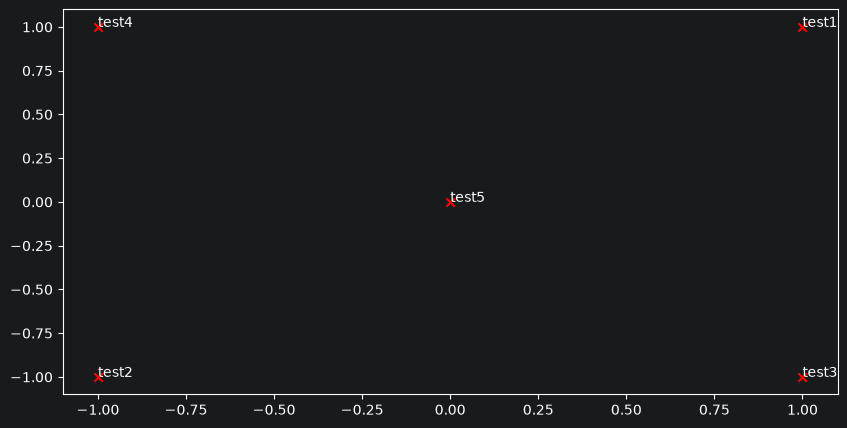

--------------------------------------------------------------------------------


In [12]:

# ---------------------
# 运行此基础检查
# 注意：该测试并不能全面验证代码的正确性。
# 生成的图像应与提供的 question_1.4_test.png 文件相似。
# ---------------------

print ("-" * 80)
print ("输出的图像：")

M_reduced_plot_test = np.array([[1, 1], [-1, -1], [1, -1], [-1, 1], [0, 0]])
word2ind_plot_test = {'test1': 0, 'test2': 1, 'test3': 2, 'test4': 3, 'test5': 4}
words = ['test1', 'test2', 'test3', 'test4', 'test5']
plot_embeddings(M_reduced_plot_test, word2ind_plot_test, words)

print ("-" * 80)


### Question 1.5: Co-Occurrence Plot Analysis [written] (3 points)

Now we will put together all the parts you have written! We will compute the co-occurrence matrix with fixed window of 4 (the default window size), over the Large Movie Review corpus. Then we will use TruncatedSVD to compute 2-dimensional embeddings of each word. TruncatedSVD returns U\*S, so we need to normalize the returned vectors, so that all the vectors will appear around the unit circle (therefore closeness is directional closeness). **Note**: The line of code below that does the normalizing uses the NumPy concept of *broadcasting*. If you don't know about broadcasting, check out
[Computation on Arrays: Broadcasting by Jake VanderPlas](https://jakevdp.github.io/PythonDataScienceHandbook/02.05-computation-on-arrays-broadcasting.html).

Run the below cell to produce the plot. It can take up to a few minutes to run.


### 问题 1.5：共现矩阵可视化分析（Co-Occurrence Plot Analysis）[书面题]（3 分）

现在，我们将把你之前编写的所有部分组合起来！

首先，我们将在大型电影评论语料库（Large Movie Review Corpus）上，使用固定的窗口大小 4（默认窗口大小）计算共现矩阵。

然后，我们将使用截断奇异值分解（Truncated SVD），计算每个单词的二维词嵌入（2-dimensional Embeddings）。

由于 TruncatedSVD 返回的是 U*S，因此我们需要对返回的向量进行归一化（Normalization），使所有向量都分布在单位圆（Unit Circle）附近（因此，向量之间的接近程度主要体现为方向上的接近程度）。

**注意：** 下面执行归一化操作的代码使用了 NumPy 中的**广播机制（Broadcasting）**。如果你不了解广播机制，可以参考 [Jake VanderPlas 的《数组计算：广播机制》（Computation on Arrays: Broadcasting）](https://jakevdp.github.io/PythonDataScienceHandbook/02.05-computation-on-arrays-broadcasting.html)。

运行下面的代码单元格以生成图像。运行过程可能需要几分钟。


正在对 5880 个单词执行截断奇异值分解（Truncated SVD）...
完成。


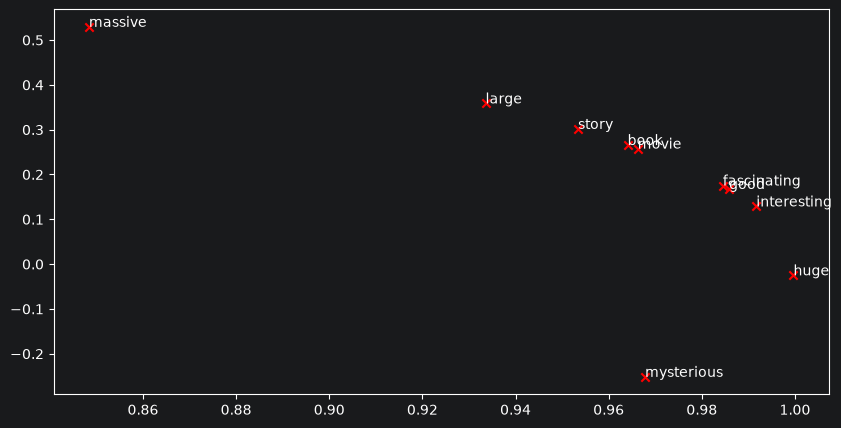

In [13]:

# -----------------------------
# 运行此代码单元格以生成图像
# ------------------------------
imdb_corpus = read_corpus()
M_co_occurrence, word2ind_co_occurrence = compute_co_occurrence_matrix(imdb_corpus)
M_reduced_co_occurrence = reduce_to_k_dim(M_co_occurrence, k=2)

# 对矩阵的每一行进行缩放（归一化），使每个行向量的长度为 1
M_lengths = np.linalg.norm(M_reduced_co_occurrence, axis=1)
M_normalized = M_reduced_co_occurrence / M_lengths[:, np.newaxis] # 广播机制（broadcasting）

words = ['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']

plot_embeddings(M_normalized, word2ind_co_occurrence, words)


**Verify that your figure matches "question_1.5.png" in the assignment zip. If not, use the figure in "question_1.5.png" to answer the next two questions.**

**请确认你生成的图像与作业压缩包中的 "question_1.5.png" 一致。如果不一致，请使用 "question_1.5.png" 中的图像回答接下来的两个问题。**

a. Find at least two groups of words that cluster together in 2-dimensional embedding space. Give an explanation for each cluster you observe.

a. 在二维词嵌入空间中，找出至少两组聚集在一起的单词（词簇）。对你观察到的每个词簇分别给出解释。

#### <font color="red">Write your answer here.</font>

1. **movie、book、story**：这三个词在二维空间中距离较近，因为它们都与文化产品以及叙事有关。
2. **good、fascinating、interesting**：这三个词聚集在一起，因为它们都可以用于正面评价作品，具有“很好”的含义。

b. What doesn't cluster together that you might think should have? Describe at least two examples.

b. 哪些你原本认为应该聚集在一起的单词，实际上却没有聚集在一起？请描述至少两个例子。

#### <font color="red">Write your answer here.</font>

1. **large、massive、huge**：这三个词都有“巨大”的含义，按语义应该聚集在一起，但图中它们的距离较远。
2. **mysterious、interesting、fascinating**：这些词都可以描述故事或电影的特点，但 mysterious 与另外两个词没有聚集在一起。

这些现象说明，基于共现矩阵的二维词嵌入不能完全准确地表示单词之间的语义相似性。

## Part 2: Prediction-Based Word Vectors (15 points)

As discussed in class, more recently prediction-based word vectors have demonstrated better performance, such as word2vec and GloVe (which also utilizes the benefit of counts). Here, we shall explore the embeddings produced by GloVe. Please revisit the class notes and lecture slides for more details on the word2vec and GloVe algorithms. If you're feeling adventurous, challenge yourself and try reading [GloVe's original paper](https://nlp.stanford.edu/pubs/glove.pdf).

Then run the following cells to load the GloVe vectors into memory. **Note**: If this is your first time to run these cells, i.e. download the embedding model, it will take a couple minutes to run. If you've run these cells before, rerunning them will load the model without redownloading it, which will take about 1 to 2 minutes.


## 第二部分：基于预测的词向量（Prediction-Based Word Vectors）（15 分）

正如课堂上讨论的那样，近年来，基于预测的词向量（Prediction-Based Word Vectors）表现出了更好的性能，例如 Word2Vec 和 GloVe（GloVe 同时也利用了词频统计信息的优势）。

在这一部分，我们将探索 GloVe 生成的词嵌入（Embeddings）。

有关 Word2Vec 和 GloVe 算法的更多细节，请重新查阅课程笔记（Class Notes）和课堂幻灯片（Lecture Slides）。

如果你想挑战自己，可以尝试阅读 [GloVe 的原始论文](https://nlp.stanford.edu/pubs/glove.pdf)。

接下来，运行以下代码单元格，将 GloVe 词向量加载到内存中。

**注意：** 如果你是第一次运行这些代码单元格，即需要下载词嵌入模型，那么运行过程可能需要几分钟。如果你之前已经运行过这些代码单元格，再次运行时将直接加载模型，而不需要重新下载，整个过程大约需要 1～2 分钟。


In [14]:
def load_embedding_model():
    """ Load GloVe Vectors
        Return:
            wv_from_bin: All 400000 embeddings, each length 200
    """
    import gensim.downloader as api
    wv_from_bin = api.load("glove-wiki-gigaword-200")
    print("Loaded vocab size %i" % len(list(wv_from_bin.index_to_key)))
    return wv_from_bin
wv_from_bin = load_embedding_model()

Loaded vocab size 400000


#### Note: If you are receiving a "reset by peer" error, rerun the cell to restart the download. 

### Reducing dimensionality of Word Embeddings
Let's directly compare the GloVe embeddings to those of the co-occurrence matrix. In order to avoid running out of memory, we will work with a sample of 40000 GloVe vectors instead.
Run the following cells to:

1. Put 40000 Glove vectors into a matrix M
2. Run `reduce_to_k_dim` (your Truncated SVD function) to reduce the vectors from 200-dimensional to 2-dimensional.
### 词嵌入的降维（Reducing Dimensionality of Word Embeddings）

现在，我们将直接比较 GloVe 词嵌入与基于共现矩阵得到的词嵌入。为了避免内存不足，我们只使用 40000 个 GloVe 词向量作为样本。

运行以下代码单元格，完成以下操作：

1. 将 40000 个 GloVe 词向量放入矩阵 `M` 中。
2. 运行 `reduce_to_k_dim`（你编写的 Truncated SVD 函数），将词向量从 200 维降至 2 维。

In [15]:
def get_matrix_of_vectors(wv_from_bin, required_words):
    """ Put the GloVe vectors into a matrix M.
        Param:
            wv_from_bin: KeyedVectors object; the 400000 GloVe vectors loaded from file
        Return:
            M: numpy matrix shape (num words, 200) containing the vectors
            word2ind: dictionary mapping each word to its row number in M
    """
    import random
    words = list(wv_from_bin.index_to_key)
    print("Shuffling words ...")
    random.seed(225)
    random.shuffle(words)
    print("Putting %i words into word2ind and matrix M..." % len(words))
    word2ind = {}
    M = []
    curInd = 0
    for w in words:
        try:
            M.append(wv_from_bin.get_vector(w))
            word2ind[w] = curInd
            curInd += 1
        except KeyError:
            continue
    for w in required_words:
        if w in words:
            continue
        try:
            M.append(wv_from_bin.get_vector(w))
            word2ind[w] = curInd
            curInd += 1
        except KeyError:
            continue
    M = np.stack(M)
    print("Done.")
    return M, word2ind

In [16]:
# -----------------------------------------------------------------
# 运行此单元格，将 200 维词嵌入降至 k 维
# 注意：此代码应该可以快速运行
# -----------------------------------------------------------------
M, word2ind = get_matrix_of_vectors(wv_from_bin, words)
M_reduced = reduce_to_k_dim(M, k=2)

# 对矩阵的每一行进行缩放（归一化），使每个行向量的长度为 1
M_lengths = np.linalg.norm(M_reduced, axis=1)
M_reduced_normalized = M_reduced / M_lengths[:, np.newaxis] # 广播机制

Shuffling words ...
Putting 400000 words into word2ind and matrix M...
Done.
正在对 400000 个单词执行截断奇异值分解（Truncated SVD）...
完成。


**Note: If you are receiving out of memory issues on your local machine, try closing other applications to free more memory on your device. You may want to try restarting your machine so that you can free up extra memory. Then immediately run the jupyter notebook and see if you can load the word vectors properly. If you still have problems with loading the embeddings onto your local machine after this, please go to office hours or contact course staff.**

**注意：如果你在本地计算机上遇到内存不足的问题，请尝试关闭其他应用程序，以释放更多内存。你也可以尝试重新启动计算机，以释放额外的内存。然后立即运行 Jupyter Notebook，检查是否能够正确加载词向量。如果仍然无法在本地计算机上加载词嵌入，请参加课程答疑时间（Office Hours）或联系课程工作人员。**

### Question 2.1: GloVe Plot Analysis [written] (3 points)

Run the cell below to plot the 2D GloVe embeddings for `['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']`.

### 问题 2.1：GloVe 可视化分析 [书面题]（3 分）

运行下面的代码单元格，绘制 `['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']` 这 10 个单词的二维 GloVe 词嵌入图。

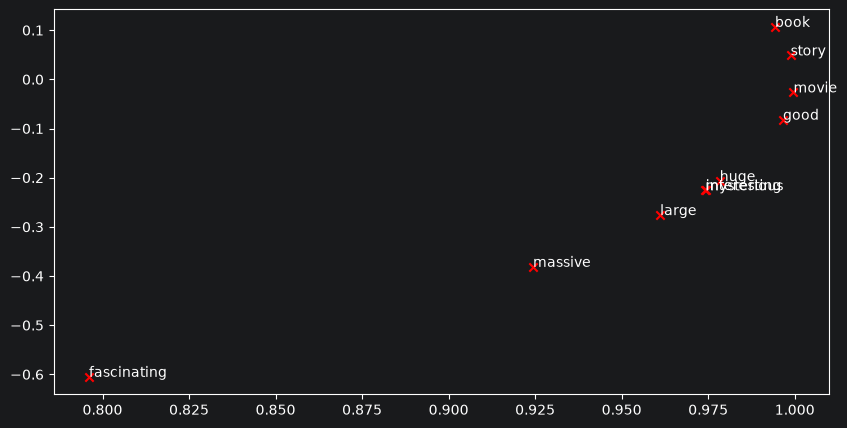

In [17]:
words = ['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']

plot_embeddings(M_reduced_normalized, word2ind, words)

**Verify that your figure matches "question_2.1.png" in the assignment zip. If not, use the figure in "question_2.1.png" (and the figure in "question_1.5.png", if applicable) to answer the next two questions.**

a. What is one way the plot is different from the one generated earlier from the co-occurrence matrix? What is one way it's similar?

a. 与之前基于共现矩阵生成的图相比，GloVe 词嵌入图有哪一个不同之处？又有哪一个相似之处？

#### <font color="red">Write your answer here.</font>

- **相同点：** 在两张图中，`movie`、`book` 和 `story` 都比较接近，说明它们具有一定的语义关联。
- **不同点：** 在共现矩阵图中，`fascinating` 与 `good`、`interesting` 比较接近；但在 GloVe 图中，`fascinating` 与这些词相距较远。

b. Why might the GloVe plot (question_2.1.png) differ from the plot generated earlier from the co-occurrence matrix (question_1.5.png)?

b. 为什么 GloVe 词嵌入图（question_2.1.png）可能与之前基于共现矩阵生成的图（question_1.5.png）不同？

#### <font color="red">Write your answer here.</font>
两张图不同主要是因为训练语料和词向量学习方法不同。

第一部分使用 150 条电影评论构建共现矩阵，再通过 Truncated SVD 得到词向量；而 GloVe 使用大规模语料，通过优化基于全局词共现统计的目标函数学习词向量。

因此，两种方法捕捉到的词语关系可能不同，最终得到的二维词嵌入分布也会不同。

### Cosine Similarity
Now that we have word vectors, we need a way to quantify the similarity between individual words, according to these vectors. One such metric is cosine-similarity. We will be using this to find words that are "close" and "far" from one another.

We can think of n-dimensional vectors as points in n-dimensional space. If we take this perspective [L1](http://mathworld.wolfram.com/L1-Norm.html) and [L2](http://mathworld.wolfram.com/L2-Norm.html) Distances help quantify the amount of space "we must travel" to get between these two points. Another approach is to examine the angle between two vectors. From trigonometry we know that:

<img src="./imgs/inner_product.png" width=20% style="float: center;"></img>

Instead of computing the actual angle, we can leave the similarity in terms of $similarity = cos(\Theta)$. Formally the [Cosine Similarity](https://en.wikipedia.org/wiki/Cosine_similarity) $s$ between two vectors $p$ and $q$ is defined as:

$$s = \frac{p \cdot q}{||p|| ||q||}, \textrm{ where } s \in [-1, 1] $$

### 余弦相似度（Cosine Similarity）

现在我们已经得到了词向量，需要一种方法来根据这些向量量化不同单词之间的相似程度。其中一种度量方法就是**余弦相似度（Cosine Similarity）**。我们将使用它来寻找彼此“接近”和“远离”的单词。

我们可以将 n 维向量看作 n 维空间中的点。从这个角度来看，[L1 距离](http://mathworld.wolfram.com/L1-Norm.html)和 [L2 距离](http://mathworld.wolfram.com/L2-Norm.html)可以帮助我们量化两个点之间的距离。另一种方法是考察两个向量之间的夹角。根据三角学知识，我们知道：

<img src="./imgs/inner_product.png" width=20% style="float: center;"></img>

我们不必计算实际的夹角，而是可以直接使用 $similarity = cos(\Theta)$ 来表示相似度。

形式上，两个向量 $p$ 和 $q$ 之间的[余弦相似度（Cosine Similarity）](https://en.wikipedia.org/wiki/Cosine_similarity) $s$ 定义为：

$$s = \frac{p \cdot q}{||p|| ||q||}, \textrm{ 其中 } s \in [-1, 1] $$

### Question 2.2: Words with Multiple Meanings (1.5 points) [code + written] 
Polysemes and homonyms are words that have more than one meaning (see this [wiki page](https://en.wikipedia.org/wiki/Polysemy) to learn more about the difference between polysemes and homonyms ). Find a word with *at least two different meanings* such that the top-10 most similar words (according to cosine similarity) contain related words from *both* meanings. For example, "leaves" has both "go_away" and "a_structure_of_a_plant" meaning in the top 10, and "scoop" has both "handed_waffle_cone" and "lowdown". You will probably need to try several polysemous or homonymic words before you find one. 

Please state the word you discover and the multiple meanings that occur in the top 10. Why do you think many of the polysemous or homonymic words you tried didn't work (i.e. the top-10 most similar words only contain **one** of the meanings of the words)?

**Note**: You should use the `wv_from_bin.most_similar(word)` function to get the top 10 most similar words. This function ranks all other words in the vocabulary with respect to their cosine similarity to the given word. For further assistance, please check the __[GenSim documentation](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.most_similar)__.

### 问题 2.2：具有多重含义的单词（1.5 分）[代码题 + 书面题]

多义词（Polysemes）和同形同音异义词（Homonyms）是具有多个含义的单词（有关两者之间区别的更多信息，请参阅此 [维基百科页面](https://en.wikipedia.org/wiki/Polysemy)）。

请找出一个**至少具有两种不同含义**的单词，使其余弦相似度最高的前 10 个单词中，包含分别与这**两种含义**相关的单词。

例如，"leaves" 的前 10 个最相似单词中，同时包含与“离开”（go_away）和“植物的结构”（a_structure_of_a_plant）相关的单词；"scoop" 的前 10 个最相似单词中，同时包含与“手持华夫蛋筒”（handed_waffle_cone）和“内幕消息”（lowdown）相关的单词。

在找到符合要求的单词之前，你可能需要尝试多个多义词或同形同音异义词。

请写出你找到的单词，以及其前 10 个最相似单词中体现出的不同含义。

你认为，为什么你尝试的许多多义词或同形同音异义词都不符合要求（即前 10 个最相似单词只体现了该单词的**一种**含义）？

**注意：** 你应该使用 `wv_from_bin.most_similar(word)` 函数获取最相似的前 10 个单词。该函数根据词汇表中其他单词与指定单词之间的余弦相似度，对它们进行排序。

如需进一步帮助，请查阅 [Gensim 官方文档](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.most_similar)。

<span style="color: yellow;"><i>Note:</i></span><br>
<i>问题的核心在于：比如 GloVe 只给 bank 一个词向量，这个向量能同时体现“银行”和“河岸”两种含义吗？</i>


In [18]:
# ------------------
# Write your implementation here.

word = "light"
similar_words = wv_from_bin.most_similar(word)

for w, score in similar_words:
    print(w, score)

# ------------------

bright 0.6242774724960327
dark 0.6141002178192139
lights 0.6013951897621155
lighter 0.558175265789032
heavy 0.5408364534378052
sunlight 0.5362919569015503
blue 0.5349379777908325
colored 0.5282376408576965
sky 0.5239452719688416
color 0.513929009437561


#### <font color="red">Write your answer here.</font>
我找到的多义词是 **`light`**，它具有“光、光线”和“轻的、重量小的”两种含义。

在余弦相似度最高的前 10 个单词中：

- **光、光线：** `bright`、`dark`、`lights`、`sunlight`。
- **轻的、重量小的：** `lighter`、`heavy`。

许多多义词不符合要求，是因为 GloVe 属于静态词嵌入模型，每个单词只有一个固定的词向量。不同含义的信息被融合在同一个向量中，而训练语料中出现频率较高的含义可能占据主导地位，因此前 10 个最相似的单词可能只反映其中一种含义。

### Question 2.3: Synonyms & Antonyms (2 points) [code + written] 

When considering Cosine Similarity, it's often more convenient to think of Cosine Distance, which is simply 1 - Cosine Similarity.

Find three words $(w_1,w_2,w_3)$ where $w_1$ and $w_2$ are synonyms and $w_1$ and $w_3$ are antonyms, but Cosine Distance $(w_1,w_3) <$ Cosine Distance $(w_1,w_2)$. 

As an example, $w_1$="happy" is closer to $w_3$="sad" than to $w_2$="cheerful". Please find a different example that satisfies the above. Once you have found your example, please give a possible explanation for why this counter-intuitive result may have happened.

You should use the the `wv_from_bin.distance(w1, w2)` function here in order to compute the cosine distance between two words. Please see the __[GenSim documentation](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.distance)__ for further assistance.

### 问题 2.3：同义词与反义词（2 分）[代码题 + 书面题]

在讨论余弦相似度（Cosine Similarity）时，使用余弦距离（Cosine Distance）通常更加方便。余弦距离的定义很简单：

$$\text{Cosine Distance} = 1 - \text{Cosine Similarity}$$

请找出三个单词 $(w_1,w_2,w_3)$，满足以下条件：

- $w_1$ 和 $w_2$ 是**同义词（Synonyms）**。
- $w_1$ 和 $w_3$ 是**反义词（Antonyms）**。
- 但它们的余弦距离满足：

$$\text{Cosine Distance}(w_1,w_3) < \text{Cosine Distance}(w_1,w_2)$$

例如，$w_1$ = `"happy"` 与其反义词 $w_3$ = `"sad"` 的距离，比与其同义词 $w_2$ = `"cheerful"` 的距离更近。

请找出一个**不同于上述示例**、且满足这一条件的例子。

找到例子后，请给出一种可能的解释，说明为什么会出现这种违反直觉的结果。

你应该使用 `wv_from_bin.distance(w1, w2)` 函数计算两个单词之间的余弦距离。

如需进一步帮助，请参阅 [Gensim 官方文档](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.distance)。

In [19]:
# ------------------
# Write your implementation here.

w1 = "hot"
w2 = "warm"
w3 = "cold"

d_synonym = wv_from_bin.distance(w1, w2)
d_antonym = wv_from_bin.distance(w1, w3)

print("同义词距离：", d_synonym)
print("反义词距离：", d_antonym)

print("是否满足题目要求：", d_antonym < d_synonym)


# ------------------

同义词距离： 0.41116726
反义词距离： 0.40621883
是否满足题目要求： True


#### <font color="red">Write your answer here.</font>
我找到的三个单词分别是：

- \(w_1\) = `hot`（热的）
- \(w_2\) = `warm`（温暖的，近义词）
- \(w_3\) = `cold`（冷的，反义词）

计算得到的余弦距离为：

- \(d(hot,warm)=0.41116726\)
- \(d(hot,cold)=0.40621883\)

因此，\(d(hot,cold)<d(hot,warm)\)，满足题目要求。

**原因分析：**

GloVe 通过词语的共现统计信息学习词向量。虽然 `hot` 和 `cold` 的含义相反，但它们经常出现在相似的上下文中，例如描述温度、天气或水的冷热程度。

因此，两者可能具有相似的上下文分布，从而学习到相近的词向量。这说明**词向量的余弦距离反映的是分布式语义相似性，并不一定能够准确区分同义词与反义词。**

### Question 2.4: Analogies with Word Vectors [written] (1.5 points)
Word vectors have been shown to *sometimes* exhibit the ability to solve analogies. 

As an example, for the analogy "man : grandfather :: woman : x" (read: man is to grandfather as woman is to x), what is x?

In the cell below, we show you how to use word vectors to find x using the `most_similar` function from the __[GenSim documentation](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.KeyedVectors.most_similar)__. The function finds words that are most similar to the words in the `positive` list and most dissimilar from the words in the `negative` list (while omitting the input words, which are often the most similar; see [this paper](https://www.aclweb.org/anthology/N18-2039.pdf)). The answer to the analogy will have the highest cosine similarity (largest returned numerical value).

### 问题 2.4：使用词向量进行类比推理（1.5 分）[书面题]

研究表明，词向量**有时**能够表现出解决类比问题的能力。

例如，对于类比关系：

**"man : grandfather :: woman : x"**

读作：“man（男人）之于 grandfather（祖父），就像 woman（女人）之于 x。”

那么，x 是什么？

在下面的代码单元格中，我们将展示如何使用词向量，通过 [Gensim 官方文档](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.KeyedVectors.most_similar)中的 `most_similar` 函数找到 x。

该函数会寻找与 `positive` 列表中的单词最相似、同时与 `negative` 列表中的单词最不相似的词（输入的单词会被排除，因为它们通常具有最高的相似度；参见[这篇论文](https://www.aclweb.org/anthology/N18-2039.pdf)）。

类比问题的答案是**余弦相似度最高的单词**，即返回结果中数值最大的单词。

In [20]:
# 运行此单元格，求解类比问题：man : grandfather :: woman : x
pprint.pprint(wv_from_bin.most_similar(positive=['woman', 'grandfather'], negative=['man']))

[('grandmother', 0.7608445286750793),
 ('granddaughter', 0.7200808525085449),
 ('daughter', 0.7168302536010742),
 ('mother', 0.7151536345481873),
 ('niece', 0.7005682587623596),
 ('father', 0.6659888029098511),
 ('aunt', 0.6623409390449524),
 ('grandson', 0.6618767976760864),
 ('grandparents', 0.644661009311676),
 ('wife', 0.6445354223251343)]


Let $m$, $g$, $w$, and $x$ denote the word vectors for `man`, `grandfather`, `woman`, and the answer, respectively. Using **only** vectors $m$, $g$, $w$, and the vector arithmetic operators $+$ and $-$ in your answer, what is the expression in which we are maximizing cosine similarity with $x$?

Hint: Recall that word vectors are simply multi-dimensional vectors that represent a word. It might help to draw out a 2D example using arbitrary locations of each vector. Where would `man` and `woman` lie in the coordinate plane relative to `grandfather` and the answer?

设 $m$、$g$、$w$ 和 $x$ 分别表示 `man`、`grandfather`、`woman` 和答案对应的词向量。

在答案中，**仅使用**向量 $m$、$g$、$w$ 以及向量运算符 $+$ 和 $-$，写出我们希望与 $x$ 的余弦相似度达到最大的向量表达式。

**提示：** 回顾一下，词向量只是用于表示单词的多维向量。你可以在二维坐标系中为每个向量任意指定一个位置，并画图辅助理解。相对于 `grandfather` 和答案，`man` 和 `woman` 应该位于坐标平面中的什么位置？

#### <font color="red">Write your answer here.</font>
$$
w + g - m
$$

### Question 2.5: Finding Analogies [code + written]  (1.5 points)
a. For the previous example, it's clear that "grandmother" completes the analogy. But give an intuitive explanation as to why the `most_similar` function gives us words like "granddaughter", "daughter", or "mother?

### 问题 2.5：寻找类比关系 [代码题 + 书面题]（1.5 分）

**a.** 对于前面的例子，显然 `grandmother`（祖母）是完成该类比关系的正确答案。但是，请给出一个**直观的解释**：为什么 `most_similar` 函数还会返回 `granddaughter`（孙女/外孙女）、`daughter`（女儿）或 `mother`（母亲）等单词？

#### <font color="red">Write your answer here.</font>

`granddaughter`（孙女）、`daughter`（女儿）和 `mother`（母亲）与 `grandmother`（祖母）具有共同的语义特征，例如都表示女性家庭成员。此外，这些词可能在训练语料中出现在相似的上下文中。由于 GloVe 捕捉的是词语之间的语义关联，而不是严格的逻辑关系，因此即使这些词不能正确完成类比，它们的词向量仍可能与目标向量具有较高的余弦相似度。

b. Find an example of analogy that holds according to these vectors (i.e. the intended word is ranked top). In your solution please state the full analogy in the form x:y :: a:b. If you believe the analogy is complicated, explain why the analogy holds in one or two sentences.

**Note**: You may have to try many analogies to find one that works!

**b.** 请找出一个在这些词向量中成立的类比例子（即预期的答案在相似度排名中位列第一）。

在答案中，请按照 **x:y :: a:b** 的形式写出完整的类比关系。

如果你认为这个类比关系比较复杂，请用一到两句话解释为什么该类比关系成立。

**注意：** 你可能需要尝试许多组类比关系，才能找到一个符合要求的例子！

In [21]:
# For example: x, y, a, b = ("", "", "", "")
# ------------------
# Write your implementation here.

x, y, a, b = ("man", "king", "woman", "queen")


# ------------------

# Test the solution
assert wv_from_bin.most_similar(positive=[a, y], negative=[x])[0][0] == b

#### <font color="red">Write your answer here.</font>

**类比关系：** `man : king :: woman : queen`

**解释：** `king` 表示男性君主，`queen` 表示女性君主。该类比关系体现了在保留君主身份的同时，将男性特征转换为女性特征。

### Question 2.6: Incorrect Analogy [code + written] (1.5 points)
a. Below, we expect to see the intended analogy "hand : glove :: foot : **sock**", but we see an unexpected result instead. Give a potential reason as to why this particular analogy turned out the way it did?

### 问题 2.6：错误的类比推理 [代码题 + 书面题]（1.5 分）

**a.** 对于下面的例子，我们原本期望得到的类比关系是：

`hand : glove :: foot : sock`

即“手之于手套，就像脚之于袜子”。

但是，实际得到的却是一个出乎意料的结果。

请给出一个可能的原因，解释为什么这个特定的类比推理会产生这样的结果。

In [22]:
pprint.pprint(wv_from_bin.most_similar(positive=['foot', 'glove'], negative=['hand']))

[('45,000-square', 0.4922032654285431),
 ('15,000-square', 0.4649604558944702),
 ('10,000-square', 0.4544755816459656),
 ('6,000-square', 0.44975775480270386),
 ('3,500-square', 0.444133460521698),
 ('700-square', 0.44257497787475586),
 ('50,000-square', 0.4356396794319153),
 ('3,000-square', 0.43486514687538147),
 ('30,000-square', 0.4330596923828125),
 ('footed', 0.43236875534057617)]


#### <font color="red">Write your answer here.</font>

这个类比推理失败的一个可能原因是 `foot` 具有多种含义，既可以表示人体的“脚”，也可以表示长度单位“英尺”。由于 GloVe 为每个单词学习一个固定的词向量，`foot` 的向量可能同时包含这两种含义的语义信息。因此，在计算目标向量时，与长度或面积相关的语义可能产生干扰，使 `45,000-square` 等面积描述词与目标向量具有较高的余弦相似度，而不是得到预期的 `sock`。

总结：GloVe 学到的不是词典中严格定义的词义，而是训练语料中词语共现模式所反映的语义信息。

b. Find another example of analogy that does *not* hold according to these vectors. In your solution, state the intended analogy in the form x:y :: a:b, and state the **incorrect** value of b according to the word vectors (in the previous example, this would be **'45,000-square'**).

**b.** 请找出另一个在这些词向量中**不成立**的类比例子。

在答案中，请按照 `x:y :: a:b` 的形式写出你预期的类比关系，并指出根据词向量计算得到的 **错误的 b 值**。

（在前面的例子中，这个错误的 b 值就是 **`'45,000-square'`**。）

In [23]:
# For example: x, y, a, b = ("", "", "", "")
# ------------------
# Write your implementation here.

x, y, a, b = ("bird", "fly", "fish", "swim")

# ------------------
pprint.pprint(wv_from_bin.most_similar(positive=[a, y], negative=[x]))
assert wv_from_bin.most_similar(positive=[a, y], negative=[x])[0][0] != b

[('salmon', 0.4980861246585846),
 ('flies', 0.476433664560318),
 ('serve', 0.471802294254303),
 ('eat', 0.46384280920028687),
 ('fishing', 0.45472317934036255),
 ('flying', 0.45176222920417786),
 ('tuna', 0.45107361674308777),
 ('catch', 0.4458751082420349),
 ('anglers', 0.4444977045059204),
 ('safely', 0.43738237023353577)]


#### <font color="red">Write your answer here.</font>

**预期类比关系：** `bird : fly :: fish : swim`

**GloVe 返回的错误答案：** `salmon`（替换为实际排名第一的单词）。

### Question 2.7: Guided Analysis of Bias in Word Vectors [written] (1 point)

It's important to be cognizant of the biases (gender, race, sexual orientation etc.) implicit in our word embeddings. Bias can be dangerous because it can reinforce stereotypes through applications that employ these models.

Run the cell below, to examine (a) which terms are most similar to "man" and "profession" and most dissimilar to "woman" and (b) which terms are most similar to "woman" and "profession" and most dissimilar to "man". Point out the difference between the list of female-associated words and the list of male-associated words, and explain how it is reflecting gender bias.

### 问题 2.7：词向量偏见的引导式分析 [书面题]（1 分）

我们必须意识到词嵌入中隐含的偏见（例如性别、种族、性取向等）。偏见可能是危险的，因为使用这些模型的应用程序可能会进一步强化刻板印象。

运行下面的代码单元，观察：

(a) 哪些词与 `man`（男性）和 `profession`（职业）最相似，同时与 `woman`（女性）最不相似。

(b) 哪些词与 `woman`（女性）和 `profession`（职业）最相似，同时与 `man`（男性）最不相似。

指出与女性相关联的词语列表和与男性相关联的词语列表之间的差异，并解释这些差异如何反映了性别偏见。

In [24]:
# 运行此代码单元
# 这里，`positive` 表示希望与之相似的单词列表，
# `negative` 表示希望与之最不相似的单词列表。

pprint.pprint(wv_from_bin.most_similar(positive=['man', 'profession'], negative=['woman']))
print()
pprint.pprint(wv_from_bin.most_similar(positive=['woman', 'profession'], negative=['man']))

[('reputation', 0.5250176787376404),
 ('professions', 0.5178037881851196),
 ('skill', 0.49046966433525085),
 ('skills', 0.49005505442619324),
 ('ethic', 0.4897659420967102),
 ('business', 0.487585186958313),
 ('respected', 0.485920250415802),
 ('practice', 0.482104629278183),
 ('regarded', 0.4778572916984558),
 ('life', 0.4760662019252777)]

[('professions', 0.5957457423210144),
 ('practitioner', 0.49884122610092163),
 ('teaching', 0.48292139172554016),
 ('nursing', 0.48211804032325745),
 ('vocation', 0.4788965880870819),
 ('teacher', 0.47160351276397705),
 ('practicing', 0.46937814354896545),
 ('educator', 0.46524327993392944),
 ('physicians', 0.4628995358943939),
 ('professionals', 0.4601394236087799)]


#### <font color="red">Write your answer here.</font>

从实验结果可以看出，男性关联词更多涉及职业声誉、技能和商业活动，例如 `reputation`、`skill`、`business` 和 `respected`；而女性关联词更多涉及教育和护理等职业，例如 `teaching`、`nursing`、`teacher` 和 `educator`。

这种差异表明，GloVe 词向量可能学习到了训练语料中的性别刻板印象，将男性更多地与职业声望和商业活动联系起来，而将女性更多地与教育和护理职业联系起来。这反映了训练语料中的社会性别偏见可能被编码到词向量中。

### Question 2.8: Independent Analysis of Bias in Word Vectors [code + written]  (1 point)

Use the `most_similar` function to find another pair of analogies that demonstrates some bias is exhibited by the vectors. Please briefly explain the example of bias that you discover.

### 问题 2.8：独立分析词向量中的偏见 [代码题 + 书面题]（1 分）

使用 `most_similar` 函数，找出另一组能够表明词向量存在某种偏见的类比关系。

请简要解释你发现的偏见实例。

In [25]:
# ------------------
# Write your implementation here.

print("Male-associated:")
pprint.pprint(wv_from_bin.most_similar(
    positive=['man', 'nurse'],
    negative=['woman']
))

print("\nFemale-associated:")
pprint.pprint(wv_from_bin.most_similar(
    positive=['woman', 'doctor'],
    negative=['man']
))


# ------------------

Male-associated:
[('doctor', 0.5821742415428162),
 ('nurses', 0.516983687877655),
 ('hospital', 0.5130800604820251),
 ('paramedic', 0.49569931626319885),
 ('physician', 0.4860961139202118),
 ('training', 0.4692404866218567),
 ('sergeant', 0.46916383504867554),
 ('care', 0.46671396493911743),
 ('trained', 0.4663393497467041),
 ('anesthetist', 0.4631572663784027)]

Female-associated:
[('nurse', 0.6813318729400635),
 ('physician', 0.6672453284263611),
 ('doctors', 0.6173422336578369),
 ('dentist', 0.5775880217552185),
 ('surgeon', 0.5691418647766113),
 ('hospital', 0.564996600151062),
 ('pregnant', 0.5649074912071228),
 ('nurses', 0.5590692758560181),
 ('medical', 0.5542059540748596),
 ('patient', 0.5518484711647034)]


#### <font color="red">Write your answer here.</font>

**类比关系：** `woman : nurse :: man : doctor`

使用 `most_similar()` 进行验证：

- `nurse + man - woman` 返回的第一名是 `doctor`，余弦相似度为 0.5822。
- `doctor + woman - man` 返回的第一名是 `nurse`，余弦相似度为 0.6813。

**偏见分析：** 这两组结果表明，GloVe 词向量将男性与医生、女性与护士建立了较强的语义关联。然而，医生和护士是不同的职业，而不是性别对应关系。这说明模型可能从训练语料中学习到了传统的职业性别刻板印象，并将其编码到了词向量中。

### Question 2.9: Thinking About Bias [written] (2 points)

a. Give one explanation of how bias gets into the word vectors. Briefly describe a real-world example that demonstrates this source of bias. Your real-world example should be focused on word vectors, as opposed to bias in other AI systems (e.g., ChatGPT).

### 问题 2.9：关于偏见的思考 [书面题]（2 分）

**a.** 请给出一个解释，说明偏见是如何进入词向量的。简要描述一个能够体现这种偏见来源的真实世界案例。

你的真实世界案例应当聚焦于**词向量**，而不是其他 AI 系统（例如 ChatGPT）中的偏见。

#### <font color="red">Write your answer here.</font>

词向量中的偏见可能来源于训练语料中已有的社会刻板印象。GloVe 通过学习词语的共现统计关系构建词向量，因此，如果语料中医生更多与男性相关联、护士更多与女性相关联，这种性别关联就可能被编码到词向量中。

例如，在 Question 2.8 中，`nurse + man - woman` 返回 `doctor`，而 `doctor + woman - man` 返回 `nurse`。这一结果体现了词向量可能学习到“男性—医生、女性—护士”的职业性别刻板印象。

b. What is one method you can use to mitigate bias exhibited by word vectors? Briefly describe a real-world example that demonstrates this method.

**b.** 请提出一种可以用于减轻词向量中所体现的偏见的方法。简要描述一个能够展示该方法的真实世界案例。


#### <font color="red">Write your answer here.</font>

一种减轻词向量偏见的方法是词向量去偏（Word Embedding Debiasing）。该方法可以先识别词向量空间中的性别方向，再减弱与性别无关的词语（如职业名称）在该方向上的分量，同时尽量保留其原有语义。

例如，对于 `doctor` 和 `nurse`，可以通过去偏处理减少它们与男性或女性之间不必要的关联，从而降低词向量将医生视为男性职业、护士视为女性职业的倾向。

# <font color="blue"> Submission Instructions</font>

1. Click the Save button at the top of the Jupyter Notebook.
2. Select Cell -> All Output -> Clear. This will clear all the outputs from all cells (but will keep the content of all cells). 
2. Select Cell -> Run All. This will run all the cells in order, and will take several minutes.
3. Once you've rerun everything, select File -> Download as -> PDF via LaTeX (If you have trouble using "PDF via LaTex", you can also save the webpage as pdf. <font color='blue'> Make sure all your solutions especially the coding parts are displayed in the pdf</font>, it's okay if the provided codes get cut off because lines are not wrapped in code cells).
4. Look at the PDF file and make sure all your solutions are there, displayed correctly. The PDF is the only thing your graders will see!
5. Submit your PDF on Gradescope.

# <font color="blue">提交说明</font>

1. 点击 Jupyter Notebook 顶部的 **Save（保存）** 按钮。
2. 选择 **Cell -> All Output -> Clear**。这将清除所有单元格的输出（但会保留所有单元格的内容）。
2. 选择 **Cell -> Run All**。这将按顺序运行所有单元格，需要几分钟时间。
3. 重新运行所有单元格后，选择 **File -> Download as -> PDF via LaTeX**（通过 LaTeX 导出为 PDF）。如果使用“PDF via LaTeX”遇到问题，也可以将网页保存为 PDF。<font color='blue'>请确保你的所有答案，尤其是代码部分，都显示在 PDF 中</font>。如果提供的代码由于代码单元格中的长行不会自动换行而被截断，这是可以接受的。
4. 检查 PDF 文件，确保所有答案都已包含在内，并且显示正确。**PDF 是评分人员唯一能够看到的文件！**
5. 在 **Gradescope** 上提交你的 PDF。